# EDA Correlation - HCMC Housing Dataset

Notebook này phân tích mối quan hệ giữa các thuộc tính của bất động sản và giá nhà (`price`) trên dataset nhà ở TP.HCM đã được làm sạch.

## 1. Import Libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Processed Dataset

In [14]:
df = pd.read_csv("../data/processed/hcm_housing_clean.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (11777, 13)

Columns:
['address', 'area', 'frontage', 'access_road', 'house_direction', 'floors', 'bedrooms', 'bathrooms', 'legal_status', 'furniture_state', 'price', 'district', 'ward']


## 3. Correlation Analysis

Chỉ các biến số được sử dụng để tính hệ số tương quan Pearson với `price`.

In [15]:
numeric_cols = [
    "area",
    "frontage",
    "access_road",
    "floors",
    "bedrooms",
    "bathrooms",
    "price"
]

numeric_df = df[numeric_cols]

numeric_df.head()

,area,frontage,access_road,floors,bedrooms,bathrooms,price
0,48.0,4.3,4.0,1.0,2.0,2.0,3.00
1,64.0,4.0,NaN,1.0,1.0,2.0,4.40
2,50.0,4.0,5.0,2.0,2.0,2.0,5.30
3,54.0,4.0,4.0,3.0,4.0,4.0,4.55
4,56.0,NaN,NaN,5.0,NaN,NaN,6.90


In [16]:
corr_matrix = numeric_df.corr()

corr_matrix

,area,frontage,access_road,floors,bedrooms,bathrooms,price
area,1.000000,0.257518,0.234815,-0.123110,0.196708,0.136598,0.360878
frontage,0.257518,1.000000,0.113248,-0.027832,0.038734,0.032078,0.089621
access_road,0.234815,0.113248,1.000000,0.051115,0.070003,0.093238,0.289108
floors,-0.123110,-0.027832,0.051115,1.000000,0.594787,0.680100,0.381747
bedrooms,0.196708,0.038734,0.070003,0.594787,1.000000,0.821235,0.433702
bathrooms,0.136598,0.032078,0.093238,0.680100,0.821235,1.000000,0.458306
price,0.360878,0.089621,0.289108,0.381747,0.433702,0.458306,1.000000


### 3.1. Correlation Heatmap

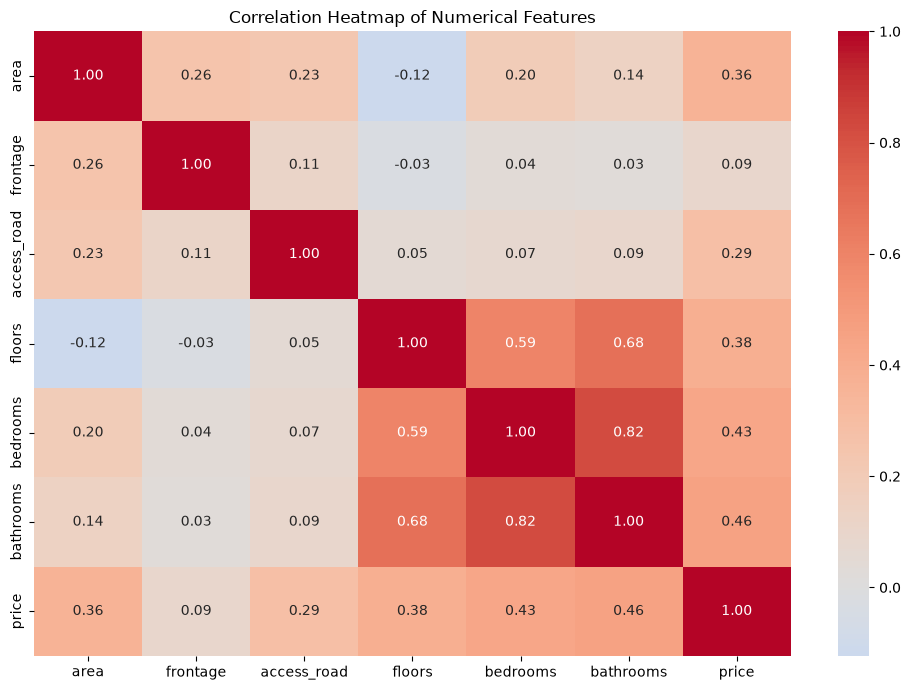

In [17]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Nhận xét

- Trong các biến số được phân tích, `bathrooms` có tương quan tuyến tính mạnh nhất với `price`, với hệ số tương quan khoảng **0.46**.
- `bedrooms` cũng có mức tương quan tương đối đáng kể với `price`, khoảng **0.43**.
- `floors` và `area` có tương quan dương mức trung bình với `price`, lần lượt khoảng **0.38** và **0.36**.
- `frontage` có tương quan rất yếu với `price`, chỉ khoảng **0.09**.
- Ngoài ra, `bedrooms` và `bathrooms` có tương quan khá mạnh với nhau (**0.82**), cho thấy các đặc trưng về số phòng có xu hướng tăng cùng nhau.
- Cần lưu ý rằng tương quan không đồng nghĩa với quan hệ nhân quả và hệ số Pearson chỉ phản ánh mối quan hệ tuyến tính.

## 4. Area - Price Relationship

Phân tích mối quan hệ giữa diện tích (`area`) và giá nhà (`price`), đồng thời so sánh giữa 5 quận/huyện có số lượng bản ghi nhiều nhất trong dataset.

In [18]:
top5_districts = df["district"].value_counts().head(5).index.tolist()

print("Top 5 districts:")
print(top5_districts)

Top 5 districts:
['Gò Vấp', 'Bình Tân', 'Thủ Đức', 'Tân Phú', 'Quận 12']


In [19]:
df_top5 = df[df["district"].isin(top5_districts)].copy()

print("Shape of top 5 districts data:", df_top5.shape)
df_top5["district"].value_counts()

Shape of top 5 districts data: (5636, 13)


district
Gò Vấp      1373
Bình Tân    1162
Thủ Đức     1145
Tân Phú     1016
Quận 12      940
Name: count, dtype: int64

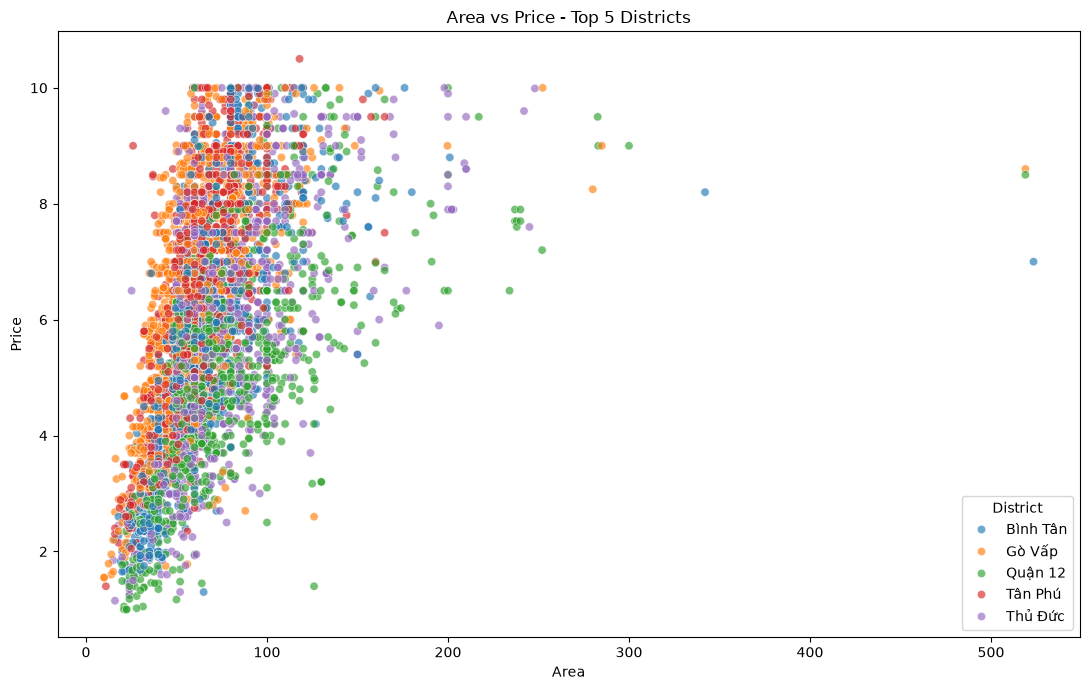

In [20]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_top5,
    x="area",
    y="price",
    hue="district",
    alpha=0.65
)

plt.title("Area vs Price - Top 5 Districts")
plt.xlabel("Area")
plt.ylabel("Price")
plt.legend(title="District")
plt.tight_layout()
plt.show()

### Nhận xét

- `area` và `price` có xu hướng tương quan dương: bất động sản có diện tích lớn hơn thường có giá cao hơn.
- Tuy nhiên, dữ liệu phân tán khá rộng, cho thấy diện tích không phải là yếu tố duy nhất quyết định giá.
- Các quận/huyện có vùng giá chồng lấn đáng kể, vì vậy cần xem xét thêm các yếu tố khác như vị trí, số tầng, số phòng ngủ và số phòng tắm.
- Dataset có một số bất động sản diện tích rất lớn, đây là các điểm hiếm cần lưu ý khi phân tích hoặc huấn luyện mô hình.

## 5. Price by Floors and Bedrooms

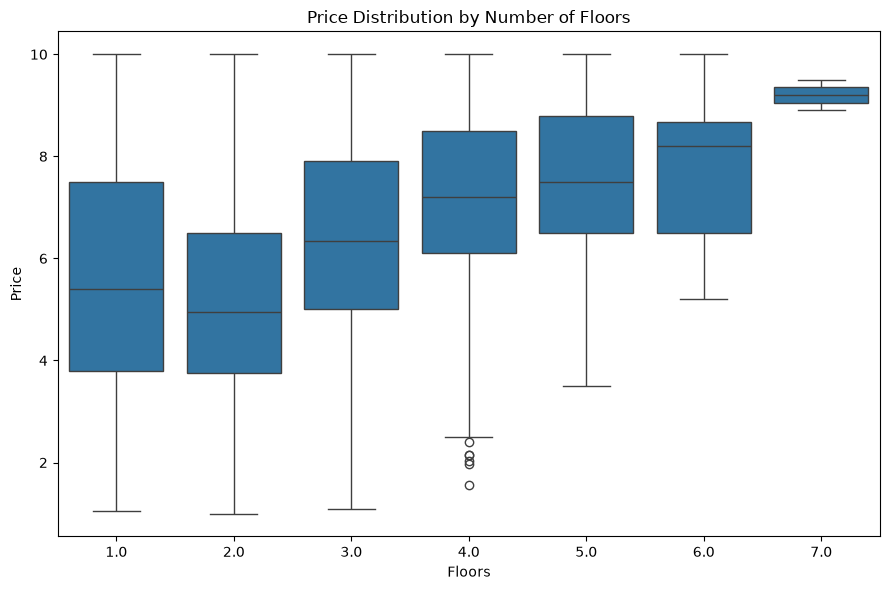

In [21]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="floors",
    y="price"
)

plt.title("Price Distribution by Number of Floors")
plt.xlabel("Floors")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### Nhận xét về `floors`

- Giá nhà có xu hướng tăng khi số tầng (`floors`) tăng.
- Median của `price` tăng khá rõ từ nhóm 2 tầng đến 6 tầng.
- Nhóm 4 tầng xuất hiện một số outlier giá thấp, cho thấy số tầng không phải yếu tố duy nhất quyết định giá.
- Nhóm 7 tầng có mức giá cao và độ phân tán nhỏ, nhưng cần kiểm tra số lượng mẫu trước khi rút ra kết luận mạnh.
- Nhìn chung, `floors` có mối liên hệ dương với `price`, phù hợp với hệ số tương quan khoảng **0.38** đã quan sát ở phần heatmap.

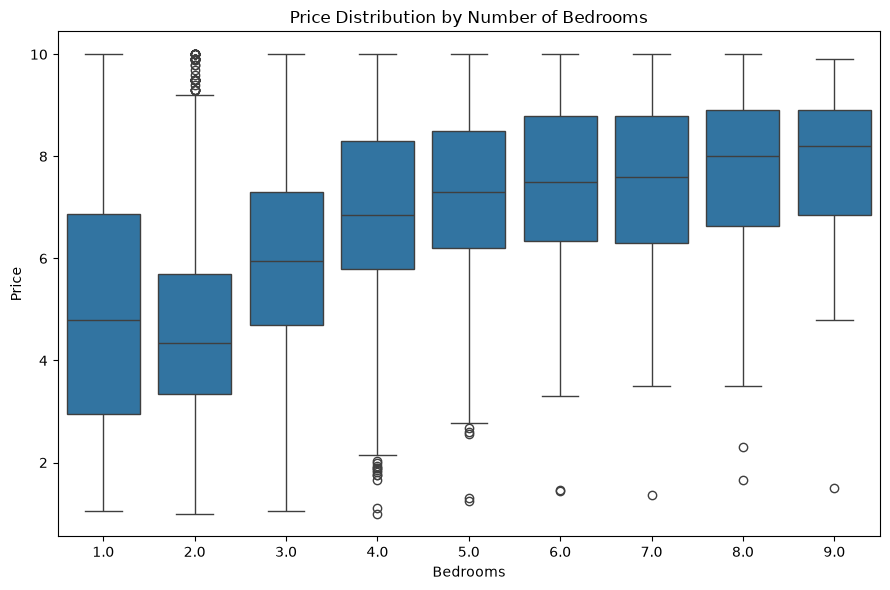

In [22]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="price"
)

plt.title("Price Distribution by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### Nhận xét về `bedrooms`

- Giá nhà có xu hướng tăng khi số phòng ngủ (`bedrooms`) tăng.
- Các nhóm từ 4 phòng ngủ trở lên có median `price` cao hơn rõ rệt so với nhóm 1–2 phòng ngủ.
- Tuy nhiên, mức giá trong từng nhóm vẫn phân tán khá rộng và xuất hiện nhiều outlier, cho thấy số phòng ngủ không phải yếu tố duy nhất quyết định giá.
- Nhìn chung, `bedrooms` có mối liên hệ dương với `price`, phù hợp với hệ số tương quan khoảng **0.43** ở phần heatmap.

### Thống kê giá theo số tầng và số phòng ngủ

In [23]:
price_by_floors = (
    df.groupby("floors")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

price_by_floors

,count,median,mean
floors,,,
1.0,906,5.40,5.52
2.0,3359,4.95,5.23
3.0,3014,6.35,6.39
4.0,2367,7.20,7.18
5.0,721,7.50,7.58
6.0,45,8.20,7.78
7.0,2,9.20,9.20


In [24]:
price_by_bedrooms = (
    df.groupby("bedrooms")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

price_by_bedrooms

,count,median,mean
bedrooms,,,
1.0,352,4.80,5.00
2.0,2520,4.35,4.66
3.0,2645,5.95,6.01
4.0,3180,6.85,6.92
5.0,914,7.30,7.31
6.0,336,7.50,7.47
7.0,121,7.60,7.51
8.0,76,8.00,7.58
9.0,35,8.20,7.69


### Nhận xét thống kê

- Median `price` nhìn chung tăng khi số tầng và số phòng ngủ tăng.
- Với `floors`, các nhóm 6 và 7 tầng có số lượng mẫu rất ít, đặc biệt 7 tầng chỉ có 2 mẫu, nên không nên rút ra kết luận mạnh từ các nhóm này.
- Với `bedrooms`, xu hướng tăng của median rõ hơn, nhưng các nhóm 8 và 9 phòng ngủ cũng có số lượng mẫu tương đối ít.
- Vì vậy, cần kết hợp cả xu hướng giá và số lượng mẫu (`count`) khi diễn giải kết quả, thay vì chỉ nhìn vào median hoặc mean.

## 6. Conclusion

Qua quá trình phân tích tương quan và trực quan hóa dữ liệu:

- Trong các biến số được xét, `bathrooms` có tương quan tuyến tính mạnh nhất với `price`, với hệ số khoảng **0.46**.
- `bedrooms` và `floors` cũng có tương quan dương với `price`, lần lượt khoảng **0.43** và **0.38**.
- `area` có tương quan dương với `price` khoảng **0.36**, cho thấy bất động sản có diện tích lớn hơn thường có xu hướng giá cao hơn, tuy nhiên dữ liệu vẫn phân tán khá rộng.
- Scatter plot theo 5 quận/huyện có nhiều bản ghi nhất cho thấy cùng một mức diện tích vẫn có thể xuất hiện nhiều mức giá khác nhau, vì vậy vị trí và các đặc trưng khác vẫn đóng vai trò quan trọng.
- Phân bố giá theo `floors` và `bedrooms` cho thấy median `price` nhìn chung tăng khi số tầng hoặc số phòng ngủ tăng.
- Một số nhóm có số lượng mẫu rất ít, đặc biệt nhóm 7 tầng, nên cần thận trọng khi diễn giải các mức giá cao ở những nhóm này.
- Các kết quả EDA này cho thấy giá nhà không phụ thuộc vào một biến duy nhất mà chịu ảnh hưởng đồng thời bởi nhiều đặc trưng.

> Hệ số tương quan Pearson chỉ phản ánh mức độ quan hệ tuyến tính và không đồng nghĩa với quan hệ nhân quả.